In [1]:
import pandas as pd
import numpy as np
import geopandas as gpd
import pyogrio
import glob
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
from adjustText import adjust_text

In [2]:
caminho_gpkg = "/home/lucas/Documentos/resenhadosdados/data/ibge_census_data_2022/niteroi_census_borders.gpkg"
print(pyogrio.list_layers(caminho_gpkg))

[['favelas_e_comunidades_censo2022' 'MultiPolygon']
 ['setores_censitarios_2022_ssagi' 'Polygon']]


In [3]:
# Inicializando tabela geral
arquivos = glob.glob("/home/lucas/Documentos/resenhadosdados/data/ticket_data/*.csv")
tabela = [pd.read_csv(arquivo) for arquivo in arquivos]
tabela = pd.concat(tabela, ignore_index=True)
tabela = tabela[["view_type", "route_name"]]
# Criando o DataFrame aux do jeito correto e estruturado
aux = pd.DataFrame({
    "view_type": tabela["view_type"].unique(),
    "route_name": tabela["route_name"].unique()
})

In [4]:
df_filtrado = pd.read_csv("estacoes.csv")
df_filtrado = pd.merge(df_filtrado, aux, on="view_type", how="left")
mapa_niteroi = gpd.read_file(caminho_gpkg, layer='setores_censitarios_2022_ssagi')
mapa_niteroi["NM_BAIRRO"] = mapa_niteroi["NM_BAIRRO"].str.upper()
mapa_favelas = gpd.read_file(caminho_gpkg, layer='favelas_e_comunidades_censo2022')

In [5]:
linhas = gpd.read_file("/home/lucas/Documentos/resenhadosdados/data/auxiliar_data/linhas_onibus_niteroi.gpkg")[["linha", "geometry"]]
linhas.drop_duplicates(subset=['linha'], keep='first', inplace=True)
linhas = pd.merge(linhas, df_filtrado, left_on="linha", right_on="route_name", how="left").dropna()

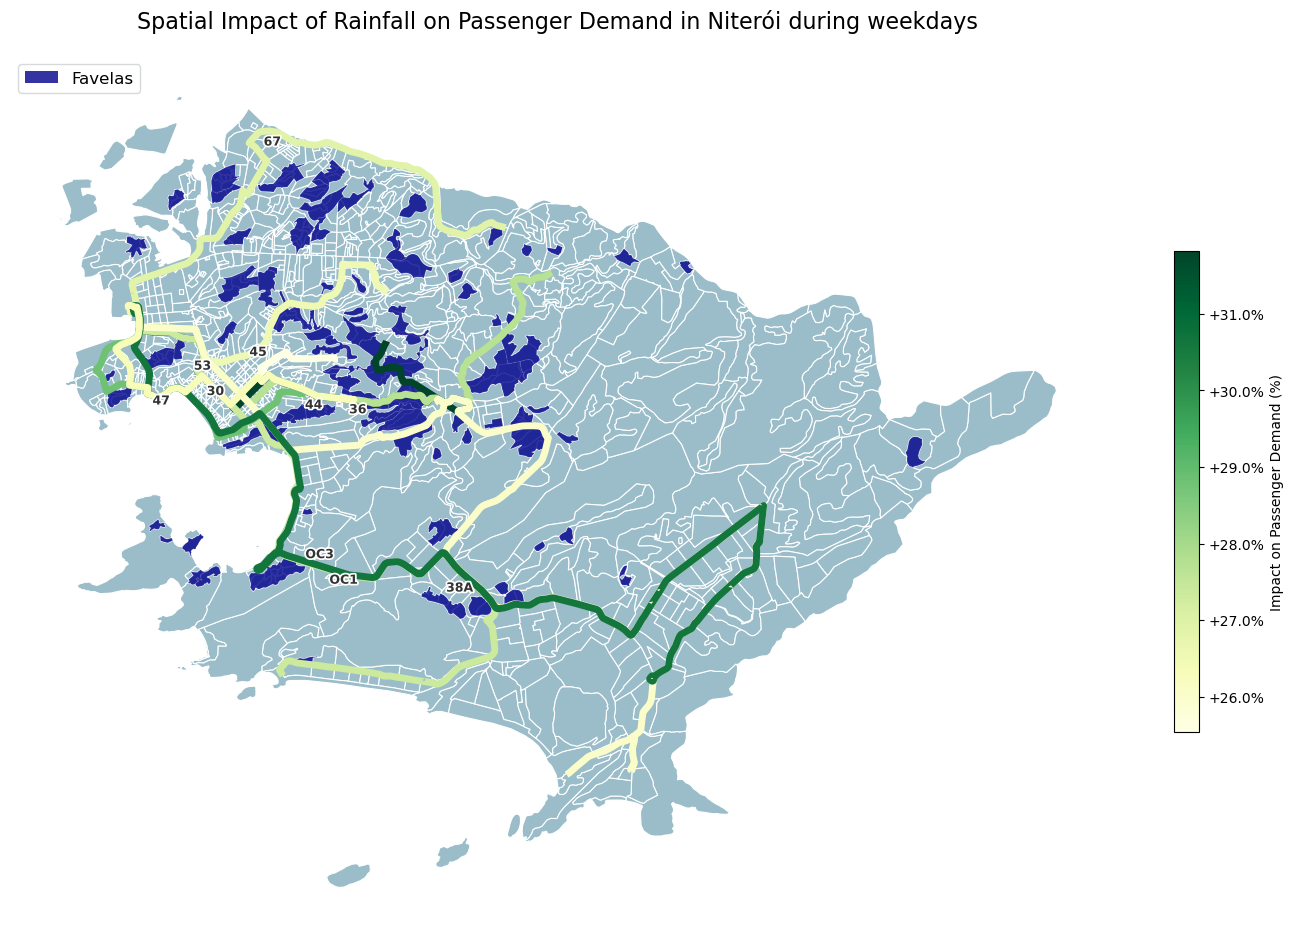

In [15]:
fig, ax = plt.subplots(figsize=(14, 10))

mapa_niteroi.plot(
    color = "#9bbdc9",
    edgecolor = "#ffffff",
    linewidth=0.8,
    ax=ax,
)

mapa_favelas.plot(
    ax=ax,
    color="darkblue",
    linewidth=1.5,
    markersize=15,
    alpha=0.8,
    label="Favelas"
)

linhas.plot(
    ax=ax,
    column="variacao_pct",      # The column containing the demand values
    cmap="YlGn",               # Colormap: Yellow -> Orange -> Red (higher demand is red)
    linewidth=5,
    legend=True,                 # Generates a colorbar for the lines
    legend_kwds={
        "label": "Impact on Passenger Demand (%)", # Updated label for percentage
        "orientation": "vertical", 
        "shrink": 0.5,           # Adjusts the size of the colorbar
        "pad": 0.05,             # Spacing between the map and the colorbar
        "format": "+%.1f%%"       # Adds the '%' symbol to the colorbar numbers (e.g., 15.0%)
    }
)

# Layer 4: Line Names (Labels) WITH AUTO-SPACING
texts = [] # Lista vazia para guardar os textos

for idx, row in linhas.iterrows():
    mid_point = row.geometry.interpolate(0.5, normalized=True)
    x = mid_point.x
    y = mid_point.y
    line_name = str(row["route_name"]) # REPLACE with your column name
    
    # Criamos o texto e guardamos na variável 'txt' (note que mudamos de ax.annotate para ax.text)
    txt = ax.text(
        x=x, 
        y=y,
        s=line_name,
        fontsize=9,
        fontweight="bold",               
        color="#333333",                 
        ha="center", 
        va="center",
        zorder=4,                        
        path_effects=[pe.withStroke(linewidth=2.5, foreground="white")]
    )
    texts.append(txt) # Adicionamos o texto na lista

# A MÁGICA ACONTECE AQUI: O adjust_text separa os textos que estão colados
adjust_text(
    texts, 
    ax=ax,
    # arrowprops=dict(arrowstyle="-", color='gray', lw=0.5, alpha=0.5) # Opcional: cria uma linha fina ligando o texto à linha caso ele seja empurrado para muito longe
)

legenda_favelas = mpatches.Patch(
    facecolor="darkblue", 
    alpha=0.8, 
    label="Favelas"
)

ax.legend(
    handles=[legenda_favelas],
    loc="upper left",
    fontsize=12, 
    frameon=True,
    facecolor="white",
    edgecolor="#ccd1d1"
)

plt.title("Spatial Impact of Rainfall on Passenger Demand in Niterói during weekdays", fontsize=16, pad=20)
plt.axis("off")
plt.tight_layout()

plt.savefig("mapa.pdf")
plt.show()